# 03 — Protocol v1.0, Stage 2A: New England proof-of-concept verdict

This notebook evaluates the pre-registered protocol (`notes/benchmark-protocol.md`) on the New England
development population. It is the **proof-of-concept verdict**. Generalization is *not* assessed here; that
is the job of the 8 held-out Census divisions, which wait on the sign-offs listed in §14 of the protocol.
Every departure from the protocol is in `prereg/deviations.md`.

**Cell**
- **Population and frame:** NE continuing non-profits, N = 20,626. Frame known on D = 2024-06-30, so prior-year information comes only from returns filed by then.
- **Register tier:** F1p, the primary (lagged revenue, expenses, assets, employees, payroll). F1 and F2 arms run alongside.
- **Design:** D1 production design, n = 1,000.
- **Monte Carlo:** R = 2,000, common random numbers, one shared fold vector per replicate.

**Embedding.** E* is selected by the pre-registered rule on the *previous* wave: TF-IDF/LSA of mission + program text, K = 16 components.

**Primary pairs**
- **P1 efficacy:** `MCAL_bmfmax@F1p+E*` vs `MCAL_bmfmax@F1p`. Same learner and folds, all IRS codes; the only difference is the text.
- **P2 production:** `FROZEN_calm_bmfmax@F1p+E*` vs `GREG_size_cat@F1p`. One bounded weight set, with heads trained on last year's respondents, against today's production GREG.

**Statistic.** GM-RE over the 10 headline variables H, with one-sided 95% bootstrap bounds.

**Decision rules**
- **Production bar:** MET if point ≥ 1.10 and lower bound ≥ 1.05; EXCLUDED if upper bound < 1.10; OPEN otherwise.
- **Any gain:** YES if lower bound > 1.00; NO if upper bound < 1.05; UNCLEAR otherwise.

In [1]:
import os, sys, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
PROJ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(PROJ, "src"))
DATA = os.environ.get("EMBAUX_DATA", "/tmp/claude-0/data")
import plotstyle; plotstyle.use()
from protocol import H_SET, H_D, H_S, R_SET
from analysis import gates, primary, no_harm, factorial, planted, cell_metrics, paired_re, rho2_min
from report import Y_LABEL
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
OUT = f"{DATA}/results/stage2_ne_v3"
df = pd.read_parquet(f"{OUT}/mc.parquet")
# D-32: the linear factorial cells, rerun as LINCAL on the same samples; the RIDGECAL rows are defective
if os.path.exists(f"{OUT}/mc_lincal.parquet"):
    df = pd.concat([df[~df.estimator.str.startswith("RIDGECAL")], pd.read_parquet(f"{OUT}/mc_lincal.parquet")], ignore_index=True)
meta = json.load(open(f"{OUT}/meta.json")); truth = meta["truth"]
pinfo = pd.read_csv(f"{OUT}/planted_info.csv")
print(f"R = {meta['R']}, estimators = {df.estimator.nunique()}, targets = {df.y.nunique()}, failures = {sum(meta['failures'].values())}")
RES = os.path.join(PROJ, "results", "stage2_ne_v3"); os.makedirs(RES, exist_ok=True)

R = 2000, estimators = 35, targets = 30, failures = 0


## 1. Validity gates (read before any efficiency number)
A failed gate quarantines the claims it guards.

| Gate | Checks |
|---|---|
| G1 | Design sanity: HT and the frozen difference estimator are unbiased |
| G2 | Random, permuted and within-stratum-permuted embeddings don't beat the twin, and a constant embedding reproduces it exactly |
| G3 | Placebo targets gain nothing |
| G4 | Text arms keep valid coverage relative to their comparator and to HT |
| G7 | No gain on register-type variables (a gain there would be leakage) |
| G8 | Masking numbers in the text changes nothing |
| G9 | The harness can detect a known large gain: last year's value of the same variable |

In [2]:
ceil = json.load(open(f"{OUT}/ceilings_P1.json"))
G = gates(df, truth, ceilings=ceil, pinfo=pinfo)
print("failure count (G1 requires <= 0.5% of replicate-estimator cells):", sum(meta["failures"].values()))
G.to_csv(f"{RES}/gates.csv", index=False)
summary = G.groupby("gate")["pass"].agg(["sum", "count"]).assign(all_pass=lambda d: d["sum"] == d["count"])
display(summary)
display(G[~G["pass"]])

failure count (G1 requires <= 0.5% of replicate-estimator cells): 0


,sum,count,all_pass
gate,,,
G1,45,45,True
G2,27,31,False
G3,13,18,False
G4,37,90,False
G5,10,10,True
G6,3,6,False
G7,4,4,True
G8,1,1,True
G9,3,3,True


,gate,item,value,pass
49,G2,N1random | y_officer_comp,1.015,False
55,G2,N2perm | y_gov_grants,1.017,False
59,G2,N2perm | y_officer_comp,1.023,False
69,G2,N3permh | y_officer_comp,1.016,False
81,G3,RIDGECAL+C+Estar vs RIDGECAL+C | y_plc_perm,9.167,False
...,...,...,...,...
182,G4,RIDGECAL+C+Estar | y_salaries,"cov 87.2 (comp 88.8, HT 94.5); varRB -99%; RB 0.25%",False
183,G4,RIDGECAL+C+Estar | y_bin_has_gov_grants,"cov 83.5 (comp 83.5, HT 94.7); varRB -100%; RB -23.21%",False
195,G6,planted rho2=0.2 phi | y_plant_r20_p0,0.243,False
197,G6,planted rho2=0.2 phi | y_plant_r20_p1,0.198,False


### 1b. Diagnosing the failed gates (protocol §9.2 diagnosis rules)
Each failure is traced to its cause, and the claims it quarantines are named.
- **G2 (noise controls):** is the failure confined to particular y, and does text beat the noise controls themselves?
- **G4 (validity):** rule T-V says a studentized-error SD > 1.10 means the variance estimator underestimates. Is it specific to text, or shared by the text-free comparators and production GREG?
- **G3 (placebo), frozen single-weight arm:** is the gain over the frozen twin a property of the twin's weights rather than text?
- **G6 (planted):** what share of a known text signal does the learner realize at n = 1,000?

In [3]:
from protocol import gm_re as _gm
tw = "MCAL_bmfmax@F1p"
d2 = []
for c in ["N1random", "N2perm", "N3permh"]:
    a = _gm(df, truth, f"{tw}+{c}", tw, H_SET, B=1000); b = _gm(df, truth, f"{tw}+Estar", f"{tw}+{c}", H_SET, B=1000)
    d2.append({"control": c, "GM-RE control vs twin (H)": a[0], "lo": a[1], "hi": a[2], "GM-RE text vs control (H)": b[0], "lo ": b[1], "hi ": b[2],
               "officer comp: control vs twin": a[3]["y_officer_comp"], "gov grants: control vs twin": a[3]["y_gov_grants"]})
print("G2 diagnosis:"); display(pd.DataFrame(d2).round(4))
cmA = cell_metrics(df[df.y.isin(H_SET + R_SET)], truth)
d4 = cmA[cmA.estimator.isin(["HT", "GREG_size_cat@F1p", "FROZEN_diff_bmfmax@F1p+Estar", tw, f"{tw}+Estar", "FROZEN_calm_bmfmax@F1p", "FROZEN_calm_bmfmax@F1p+Estar"])] \
    .groupby("estimator")[["var_rb_pct", "stud_sd", "coverage_pct"]].median()
print("G4 diagnosis (medians over the 14 real y): variance relative bias, studentized-error SD, coverage"); display(d4.round(3))
d3 = [{"pair": f"{a} vs {b}", "y": y, **dict(zip(["re", "lo", "hi"], paired_re(df, truth, a, b, y, B=1000)))}
      for a, b in [("FROZEN_calm_bmfmax@F1p+Estar", "FROZEN_calm_bmfmax@F1p"), ("FROZEN_calm_bmfmax@F1p", "GREG_size_cat@F1p"),
                   ("FROZEN_calm_bmfmax@F1p+Estar", "GREG_size_cat@F1p"), (f"{tw}+Estar", tw)] for y in ["y_plc_noise"]]
print("G3 diagnosis (size-proportional noise placebo y = x~ * lognormal(0, 2)):"); display(pd.DataFrame(d3).round(3))

G2 diagnosis:


,control,GM-RE control vs twin (H),lo,hi,GM-RE text vs control (H),lo,hi,officer comp: control vs twin,gov grants: control vs twin
0,N1random,0.9932,0.9895,0.9971,1.0512,1.0442,1.0589,1.0148,0.9892
1,N2perm,0.9992,0.9955,1.0033,1.0449,1.0376,1.0528,1.0234,1.0169
2,N3permh,0.9962,0.9925,0.9998,1.0481,1.0411,1.0557,1.0156,1.0153


G4 diagnosis (medians over the 14 real y): variance relative bias, studentized-error SD, coverage


,var_rb_pct,stud_sd,coverage_pct
estimator,,,
FROZEN_calm_bmfmax@F1p,-17.319,1.199,89.875
FROZEN_calm_bmfmax@F1p+Estar,-15.233,1.191,90.175
FROZEN_diff_bmfmax@F1p+Estar,3.150,1.026,94.300
GREG_size_cat@F1p,-9.998,1.165,90.725
HT,4.553,1.054,94.025
MCAL_bmfmax@F1p,-15.610,1.193,90.075
MCAL_bmfmax@F1p+Estar,-14.709,1.195,89.800


G3 diagnosis (size-proportional noise placebo y = x~ * lognormal(0, 2)):


,pair,y,re,lo,hi
0,FROZEN_calm_bmfmax@F1p+Estar vs FROZEN_calm_bmfmax@F1p,y_plc_noise,1.064,1.013,1.123
1,FROZEN_calm_bmfmax@F1p vs GREG_size_cat@F1p,y_plc_noise,0.918,0.869,0.967
2,FROZEN_calm_bmfmax@F1p+Estar vs GREG_size_cat@F1p,y_plc_noise,0.977,0.937,1.016
3,MCAL_bmfmax@F1p+Estar vs MCAL_bmfmax@F1p,y_plc_noise,0.984,0.958,1.010


## 2. Primary pairs and secondaries

In [4]:
P = primary(df, truth)
P.to_csv(f"{RES}/primary_pairs.csv", index=False)
show = P[["pair", "set", "gm_re", "lo95", "hi95", "production_bar", "any_gain"]].copy()
display(show.round(3))

,pair,set,gm_re,lo95,hi95,production_bar,any_gain
0,P1 efficacy,H,1.044,1.037,1.052,EXCLUDED,YES
1,P1 efficacy,H_D,1.056,1.044,1.069,EXCLUDED,YES
2,P1 efficacy,H_S,1.033,1.026,1.040,EXCLUDED,YES
3,P1' (NTEE10 twin),H,1.086,1.076,1.096,EXCLUDED,YES
4,P1' (NTEE10 twin),H_D,1.136,1.118,1.154,MET,YES
5,P1' (NTEE10 twin),H_S,1.038,1.031,1.046,EXCLUDED,YES
6,P2 production,H,1.121,1.108,1.134,MET,YES
7,P2 production,H_D,1.226,1.199,1.253,MET,YES
8,P2 production,H_S,1.025,1.019,1.031,EXCLUDED,YES
9,P2-twin (no text),H,1.071,1.059,1.082,EXCLUDED,YES


### Per-variable RE for P1 and P2 (headline set H)

In [5]:
per = P[P.set == "H"].set_index("pair")[[f"re:{y}" for y in H_SET]]
per.columns = [Y_LABEL.get(c[3:], c[3:]) for c in per.columns]
display(per.T.round(3))

pair,P1 efficacy,P1' (NTEE10 twin),P2 production,P2-twin (no text),P2' (current-sample single weight),P2 text increment (frozen text vs frozen twin),S-F1 (no payroll register),S-F2 (full prior return),secondary: E* K=64,ladder L4: MiniLM T2
Government grants,1.084,1.175,1.236,1.116,1.168,1.107,1.090,1.012,1.139,1.045
Contributions,1.078,1.207,1.354,1.240,1.287,1.092,1.080,1.020,1.068,1.037
Program service revenue,1.026,1.085,1.179,1.101,1.177,1.071,1.018,0.999,1.009,1.019
Fundraising expenses,1.060,1.148,1.411,1.289,1.329,1.094,1.046,1.006,1.018,1.002
Officer compensation,1.033,1.068,0.996,0.975,0.975,1.021,1.037,0.966,1.027,1.023
Volunteers (capped 10k),1.019,1.024,1.033,1.015,1.037,1.017,1.017,1.004,1.014,1.011
Share with volunteers,1.025,1.019,0.999,1.002,0.999,0.997,1.024,1.022,1.017,1.025
Share granting to individuals,1.098,1.105,1.072,1.013,1.093,1.058,1.099,1.095,1.087,1.058
Share with foreign activities,1.008,1.026,1.014,1.008,1.024,1.006,1.007,1.003,1.022,1.006
Share lobbying,1.015,1.020,1.008,0.998,1.003,1.010,1.015,1.023,1.010,1.010


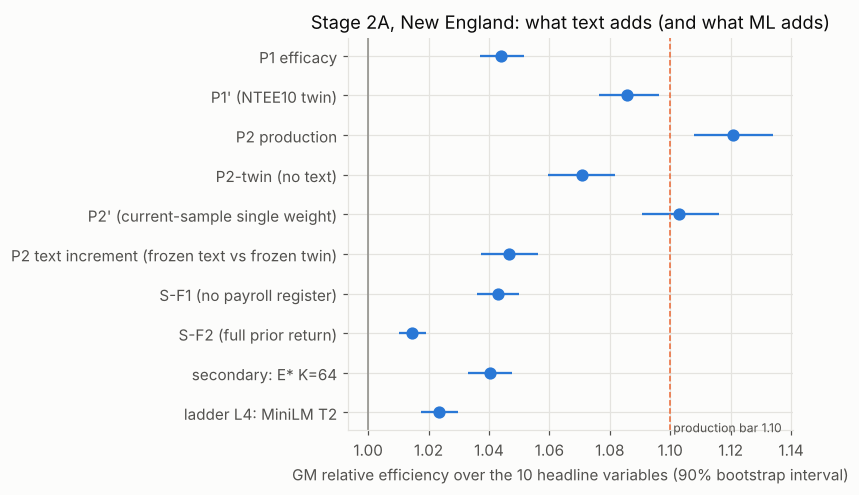

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
rows = P[(P.set == "H")].reset_index(drop=True)
yy = np.arange(len(rows))
ax.errorbar(rows.gm_re, yy, xerr=[rows.gm_re - rows.lo95, rows.hi95 - rows.gm_re], fmt="o", color=plotstyle.SERIES[0], capsize=0, lw=1.5)
ax.axvline(1.0, color=plotstyle.NEUTRAL, lw=1); ax.axvline(1.10, color=plotstyle.SERIES[1], lw=1, ls="--")
ax.text(1.101, len(rows) - 0.5, "production bar 1.10", color=plotstyle.TEXT2, fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(rows.pair); ax.invert_yaxis()
ax.set_xlabel("GM relative efficiency over the 10 headline variables (90% bootstrap interval)")
ax.set_title("Stage 2A, New England: what text adds (and what ML adds)")
plt.tight_layout(); plt.savefig(f"{RES}/primary_pairs.png", dpi=150); plt.show()

### P2 no-harm condition
Production also requires that no variable is made worse: min point RE ≥ 0.95, and no upper bound below 0.95.

In [7]:
nh, ok = no_harm(df, truth, "FROZEN_calm_bmfmax@F1p+Estar", "GREG_size_cat@F1p")
nh["label"] = nh.y.map(lambda y: Y_LABEL.get(y, y))
display(nh.round(3)); print("no-harm condition holds:", ok)

,y,re,lo95,hi95,label
0,y_gov_grants,1.236,1.184,1.287,Government grants
1,y_contrib,1.354,1.296,1.415,Contributions
2,y_prog_rev,1.179,1.133,1.226,Program service revenue
3,y_fundraising_exp,1.411,1.348,1.474,Fundraising expenses
4,y_officer_comp,0.996,0.973,1.021,Officer compensation
5,y_volunteers_cap10k,1.033,1.018,1.049,Volunteers (capped 10k)
6,y_bin_has_volunteers,0.999,0.990,1.006,Share with volunteers
7,y_bin_grants_to_indiv_us,1.072,1.051,1.092,Share granting to individuals
8,y_bin_foreign_activities,1.014,1.000,1.027,Share with foreign activities
9,y_bin_lobbying,1.008,0.998,1.017,Share lobbying


no-harm condition holds: True


## 3. Attribution: learner (A) × codes (B) × text (C), Shapley shares of log RE
The 8-cell factorial runs on the same samples and folds. Shares sum to log RE(all three on | none).
- Factor A is the learner: ratio-scale ridge on log features vs a linear raw-scale learner.
- Every cell other than GREG uses the same cross-fitting and model calibration.
- The linear cells are LINCAL (D-32). The originally run RIDGECAL cells failed G3/G4.

In [8]:
F_t, F_mean = factorial(df, truth)
F_t["label"] = F_t.y.map(lambda y: Y_LABEL.get(y, y))
display(F_t.round(4)); print("mean over H:"); display(F_mean.round(4).to_frame("mean"))
# a share is only meaningful when the total gain is positive
print("text share of the total log gain:", round(F_mean.phi_C_text / F_mean.log_RE_total, 3) if F_mean.log_RE_total > 0.01 else "n/a (total log gain <= 0.01)")

,y,log_RE_total,phi_A_learner,phi_B_codes,phi_C_text,label
0,y_gov_grants,0.1719,3.9510,-4.0746,0.2955,Government grants
1,y_contrib,0.2295,4.3498,-4.4293,0.3090,Contributions
2,y_prog_rev,0.0990,3.8313,-3.5801,-0.1522,Program service revenue
3,y_fundraising_exp,0.3131,3.6051,-3.6335,0.3416,Fundraising expenses
4,y_officer_comp,-0.0330,3.6201,-3.1051,-0.5479,Officer compensation
5,y_volunteers_cap10k,0.0166,2.8628,-1.9832,-0.8630,Volunteers (capped 10k)
6,y_bin_has_volunteers,0.0187,4.6172,-4.3576,-0.2409,Share with volunteers
7,y_bin_grants_to_indiv_us,0.0888,3.2791,-3.5789,0.3885,Share granting to individuals
8,y_bin_foreign_activities,0.0039,4.6321,-4.6358,0.0076,Share with foreign activities
9,y_bin_lobbying,0.0216,3.0042,-2.8945,-0.0881,Share lobbying


mean over H:


,mean
log_RE_total,0.0930
phi_A_learner,3.7753
phi_B_codes,-3.6273
phi_C_text,-0.0550


text share of the total log gain: -0.591


## 4. Planted-signal recovery: what the harness can detect
The planted columns carry a text signal with a *known* same-class partial ρ². For each level we compare the
realized Monte Carlo RE of text vs twin with the theoretical 1/(1 − ρ²).

ρ²_min(1,000) is the smallest planted ρ² at which a single-variable MET (point ≥ 1.10, lower bound ≥ 1.05)
passes in at least 2 of 3 plantings. A null on real data is then stated as "text partial ρ² < ρ²_min".

In [9]:
PL = planted(df, truth, pinfo)
display(PL.round(3))
r_strict, r_lenient, met = rho2_min(PL)
print("plantings meeting the bar by level:", met, "| rho2_min(1000) =", r_strict, "(3 of 3; protocol-equivalent) | lenient 2 of 3:", r_lenient)
print("protocol-form planted family (diagnostic, D-3): achieved rho2 by a =",
      pinfo[pinfo.family == "pr"].groupby("a").rho2_achieved.mean().round(3).to_dict())

,y,rho2,rho2_achieved,re_mc,lo95,hi95,re_theory,phi
0,y_plant_r00_p0,0.00,-0.007,0.997,0.985,1.010,1.000,NaN
1,y_plant_r05_p0,0.05,0.050,0.997,0.982,1.012,1.053,-0.064
2,y_plant_r10_p0,0.10,0.100,1.011,0.991,1.030,1.111,0.102
3,y_plant_r20_p0,0.20,0.200,1.056,1.028,1.085,1.250,0.243
4,y_plant_r00_p1,0.00,-0.011,0.987,0.974,1.001,1.000,NaN
5,y_plant_r05_p1,0.05,0.050,0.995,0.977,1.011,1.053,-0.102
6,y_plant_r10_p1,0.10,0.100,1.009,0.990,1.029,1.111,0.086
7,y_plant_r20_p1,0.20,0.200,1.045,1.022,1.073,1.250,0.198
8,y_plant_r00_p2,0.00,-0.004,0.990,0.979,1.001,1.000,NaN
9,y_plant_r05_p2,0.05,0.050,1.004,0.991,1.016,1.053,0.073


plantings meeting the bar by level: {0.0: 0, 0.05: 0, 0.1: 0, 0.2: 0} | rho2_min(1000) = None (3 of 3; protocol-equivalent) | lenient 2 of 3: None
protocol-form planted family (diagnostic, D-3): achieved rho2 by a = {0.5: -0.036, 1.0: -0.045, 2.0: -0.051, 3.0: -0.045}


## 5. Controls and pitfall demonstrations

In [10]:
cm = cell_metrics(df, truth)
ctl = ["MCAL_bmfmax@F1p+N1random", "MCAL_bmfmax@F1p+N2perm", "MCAL_bmfmax@F1p+N3permh", "MCAL_bmfmax@F1p+Estar_nonum",
       "MCAL_bmfmax@F1p+Estar:nocf", "SYN_bmfmax@F1p+Estar", "MCAL_bmfmax@F1p+Estar", "MCAL_bmfmax@F1p"]
sub = cm[cm.estimator.isin(ctl) & cm.y.isin(H_SET)]
print("Relative bias (%):"); display(sub.pivot(index="y", columns="estimator", values="rb_pct")[ctl].round(2))
print("95% CI coverage (%):"); display(sub.pivot(index="y", columns="estimator", values="coverage_pct")[[c for c in ctl if not c.startswith("SYN")]].round(1))

Relative bias (%):


estimator,MCAL_bmfmax@F1p+N1random,MCAL_bmfmax@F1p+N2perm,MCAL_bmfmax@F1p+N3permh,MCAL_bmfmax@F1p+Estar_nonum,MCAL_bmfmax@F1p+Estar:nocf,SYN_bmfmax@F1p+Estar,MCAL_bmfmax@F1p+Estar,MCAL_bmfmax@F1p
y,,,,,,,,
y_bin_foreign_activities,1.07,1.07,1.09,0.90,3.05,1.27,0.90,1.04
y_bin_grants_to_indiv_us,0.51,0.54,0.54,0.28,0.31,0.01,0.27,0.53
y_bin_has_volunteers,0.03,0.04,0.04,0.01,0.08,-0.01,0.01,0.03
y_bin_lobbying,0.53,0.52,0.52,0.31,0.91,0.24,0.31,0.51
y_contrib,0.29,0.28,0.32,0.26,0.62,0.95,0.26,0.27
y_fundraising_exp,0.49,0.48,0.55,0.40,2.14,4.71,0.40,0.33
y_gov_grants,0.45,0.34,0.35,0.32,1.59,3.79,0.33,0.47
y_officer_comp,0.58,0.55,0.56,0.61,2.41,1.58,0.61,0.59
y_prog_rev,0.20,0.20,0.20,0.22,0.16,0.01,0.22,0.19


95% CI coverage (%):


estimator,MCAL_bmfmax@F1p+N1random,MCAL_bmfmax@F1p+N2perm,MCAL_bmfmax@F1p+N3permh,MCAL_bmfmax@F1p+Estar_nonum,MCAL_bmfmax@F1p+Estar:nocf,MCAL_bmfmax@F1p+Estar,MCAL_bmfmax@F1p
y,,,,,,,
y_bin_foreign_activities,92.4,92.4,92.4,92.2,90.5,92.2,92.4
y_bin_grants_to_indiv_us,93.4,93.3,93.4,93.2,89.8,93.2,93.3
y_bin_has_volunteers,93.8,94.0,94.0,94.2,88.6,94.1,93.9
y_bin_lobbying,93.4,93.4,93.5,93.4,92.0,93.3,93.5
y_contrib,90.3,90.4,89.8,89.0,81.0,89.3,89.8
y_fundraising_exp,87.8,88.1,88.0,87.4,76.7,87.5,88.4
y_gov_grants,88.3,88.5,88.3,88.9,72.2,88.6,88.3
y_officer_comp,88.8,88.7,89.0,88.8,81.6,88.7,88.9
y_prog_rev,89.4,90.0,89.8,89.8,80.0,90.0,90.1


## 6. Real-world translation of P2
- The take-some sample saving at equal precision is σ ≈ 1 − 1/RE.
- **The binding variable sets the saving for a multipurpose survey.**
- CV bands use the Statistics Canada letters (A < 5%, B < 10%, C < 15%, D < 25%, E < 35%, F ≥ 35%).

In [11]:
from report import cv_band
rows = []
for y in H_SET + R_SET:
    b0 = cm[(cm.estimator == "GREG_size_cat@F1p") & (cm.y == y)].rrmse_pct.iat[0]
    p2 = cm[(cm.estimator == "FROZEN_calm_bmfmax@F1p+Estar") & (cm.y == y)].rrmse_pct.iat[0]
    re = (b0 / p2) ** 2
    rows.append({"variable": Y_LABEL.get(y, y), "CV B0 %": b0, "band B0": cv_band(b0), "CV P2 %": p2, "band P2": cv_band(p2),
                 "RE": re, "take-some saving %": 100 * (1 - 1 / re)})
tr = pd.DataFrame(rows).round(2); display(tr)
tr.to_csv(f"{RES}/real_world_translation.csv", index=False)

,variable,CV B0 %,band B0,CV P2 %,band P2,RE,take-some saving %
0,Government grants,8.54,B,7.68,B,1.24,19.06
1,Contributions,3.51,A,3.02,A,1.35,26.13
2,Program service revenue,1.51,A,1.39,A,1.18,15.18
3,Fundraising expenses,6.36,B,5.36,B,1.41,29.12
4,Officer compensation,6.49,B,6.51,B,1.00,-0.39
5,Volunteers (capped 10k),18.06,D,17.77,D,1.03,3.19
6,Share with volunteers,4.39,A,4.40,A,1.00,-0.12
7,Share granting to individuals,12.44,C,12.02,C,1.07,6.71
8,Share with foreign activities,14.66,C,14.56,C,1.01,1.34
9,Share lobbying,12.31,C,12.26,C,1.01,0.80


### Binding constraint (protocol §8.7)
Default CV targets are assumptions until the user sets them (U5):
- national totals: CV ≤ 5% for government grants, contributions and fundraising; ≤ 10% for volunteers;
- national proportions: absolute SE ≤ 1.0 pp.

The take-some sample needed for each target is approximated as n_TS × (CV / target)², ignoring the fpc. The survey's n is set by the **largest** requirement.

In [12]:
n_ts = int(json.load(open(f"{OUT}/design.json"))["design"]["take_all_n"])
n_ts = 1000 - n_ts
N = 20626
targets = {"y_gov_grants": ("cv", 5.0), "y_contrib": ("cv", 5.0), "y_fundraising_exp": ("cv", 5.0), "y_volunteers_cap10k": ("cv", 10.0),
           **{y: ("se_pp", 1.0) for y in H_SET if y.startswith("y_bin_")}}
req = []
for y, (kind, tgt) in targets.items():
    for sysname, est in [("B0 (production GREG)", "GREG_size_cat@F1p"), ("P2 (frozen text system)", "FROZEN_calm_bmfmax@F1p+Estar")]:
        cv = cm[(cm.estimator == est) & (cm.y == y)].rrmse_pct.iat[0]
        crit = cv if kind == "cv" else cv * truth[y] / N          # SE in pp of a proportion = CV% x p
        req.append({"variable": Y_LABEL.get(y, y), "system": sysname, "achieved": crit, "target": tgt, "n_TS needed": n_ts * (crit / tgt) ** 2})
req = pd.DataFrame(req)
w = req.pivot(index="variable", columns="system", values="n_TS needed").round(0); display(w)
bind = req.groupby("system").apply(lambda g: g.loc[g["n_TS needed"].idxmax(), ["variable", "n_TS needed"]])
display(bind)
b0, p2n = bind["n_TS needed"].iloc[0], bind["n_TS needed"].iloc[1]
print(f"binding-constraint take-some saving: {100 * (1 - p2n / b0):.1f}% (B0 needs {b0:.0f}, P2 needs {p2n:.0f}; current n_TS = {n_ts})")
req.to_csv(f"{RES}/binding_constraint.csv", index=False)

system,B0 (production GREG),P2 (frozen text system)
variable,,
Contributions,391.0,289.0
Fundraising expenses,1286.0,912.0
Government grants,2315.0,1874.0
Share granting to individuals,1797.0,1677.0
Share lobbying,398.0,395.0
Share with foreign activities,316.0,312.0
Share with volunteers,5287.0,5293.0
Volunteers (capped 10k),2590.0,2507.0


,variable,n_TS needed
system,,
B0 (production GREG),Share with volunteers,5286.586446
P2 (frozen text system),Share with volunteers,5292.670341


binding-constraint take-some saving: -0.1% (B0 needs 5287, P2 needs 5293; current n_TS = 794)


## 7. Verdict (protocol §9.6)
§9.6 reads: "HARNESS NOT VALIDATED: any of G1–G9 fails in more than one division after diagnosis, or fails in the
NE proof-of-concept cell."

Under that letter, any failed gate makes the NE verdict **HARNESS NOT VALIDATED**. The diagnosed reading, which
names each failure's cause and the claims it quarantines, is printed below. FINDINGS.md uses both.

In [13]:
failed = sorted(G.loc[~G["pass"], "gate"].unique())
print("gates with any failed item:", failed)
print("strict §9.6 verdict:", "HARNESS NOT VALIDATED" if failed else "gates clean")
p1 = P[(P.pair == "P1 efficacy") & (P.set == "H")].iloc[0]; p2 = P[(P.pair == "P2 production") & (P.set == "H")].iloc[0]
print(f"P1 efficacy  GM-RE {p1.gm_re:.3f} ({p1.lo95:.3f}-{p1.hi95:.3f}): production bar {p1.production_bar}, any gain {p1.any_gain}")
print(f"P2 production GM-RE {p2.gm_re:.3f} ({p2.lo95:.3f}-{p2.hi95:.3f}): production bar {p2.production_bar}, any gain {p2.any_gain}; no-harm {ok}; "
      f"G4 for the P2 text arm on every y: {bool(G[(G.gate == 'G4') & G.item.str.startswith('FROZEN_calm_bmfmax+Estar')]['pass'].all())}")

gates with any failed item: ['G2', 'G3', 'G4', 'G6']
strict §9.6 verdict: HARNESS NOT VALIDATED
P1 efficacy  GM-RE 1.044 (1.037-1.052): production bar EXCLUDED, any gain YES
P2 production GM-RE 1.121 (1.108-1.134): production bar MET, any gain YES; no-harm True; G4 for the P2 text arm on every y: False
